# Projecte: BICITIERRA - Neteja de dades de sales history

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# tin en compte que la ruta el dataset por variar en funció de com tingues organitzada la carpeta del projecte
df_sales = pd.read_csv('../dades/sales_history.csv')
#3. Després mostre les 15 primeres línies.
df_sales.head(15)

,month,channel,product_line,region,marketing_spend,avg_discount,stock_units,website_sessions,sales_units,revenue,marketing_budget,planned_discount,list_price,campaign,days_in_month,closing_stock_units,stockout
0,2021-01,store,urban,coast,2190.14,0.047,150,3763.0,95,38024.70,2002.85,0.034,420.0,none,31,55,0
1,2021-01,store,urban,inland,3281.92,0.074,88,4664.0,82,31891.44,3016.71,0.062,420.0,none,31,6,0
2,2021-01,store,urban,metro,3347.16,0.050,141,5073.0,141,56259.00,3386.79,0.046,420.0,none,31,0,1
3,2021-01,store,mountain,coast,2530.35,0.037,66,3705.0,56,37210.32,2396.99,0.028,690.0,none,31,10,0
4,2021-01,store,mountain,inland,2136.16,0.101,61,3318.0,44,27293.64,2272.67,0.092,690.0,none,31,17,0
5,2021-01,store,mountain,metro,3566.49,0.011,48,4541.0,48,32755.68,3308.59,0.012,690.0,none,31,0,1
6,2021-01,store,electric,coast,1706.78,0.075,57,2693.0,39,53391.00,1811.32,0.071,1480.0,none,31,18,0
7,2021-01,store,electric,inland,3840.56,0.056,17,4483.0,17,23751.04,3652.61,0.047,1480.0,none,31,0,1
8,2021-01,store,electric,metro,2578.57,0.023,55,3765.0,48,69406.08,2722.88,0.043,1480.0,none,31,7,0
9,2021-01,ecommerce,urban,coast,3067.64,0.045,189,7085.0,130,52143.00,3138.31,0.046,420.0,none,31,59,0


### Pas 1: Descarregar les dades i construir el DataFrame

In [3]:
# Mostrem l'estructura del DataFrame (noms de les columnes i tipus de dades)
print("Shape:", df_sales.shape) # Mostra la quantitat de files i columnes
print("\nColumns and data types:") # Mostra els noms de les columnes i els tipus de dades
print(df_sales.dtypes)


Shape: (1188, 17)

Columns and data types:
month                      str
channel                    str
product_line               str
region                     str
marketing_spend        float64
avg_discount           float64
stock_units              int64
website_sessions       float64
sales_units              int64
revenue                float64
marketing_budget       float64
planned_discount       float64
list_price             float64
campaign                   str
days_in_month            int64
closing_stock_units      int64
stockout                 int64
dtype: object


### Pas 2: Preprocessament de les dades

Abans de començar a entrenar els models, és important fer un preprocessament de les dades. 

- Comproveu si hi ha valors nuls i, si n'hi ha, decidiu com tractar-los (per exemple, eliminant les files amb valors nuls o omplint-los amb la mitjana o la mediana)
- Comproveu si hi ha variables categòriques (no numèriques). Decidiu què fer amb elles.
- Mireu si hi ha molta diferència entre les magnituds de les diferents característiques i decidiu si seria convenient normalitzar o estandarditzar algunes d'elles.

In [4]:
# Comprovem si hi ha valors nuls al DataFrame
print("\nNull values in each column:")
print(df_sales.isnull().sum())


Null values in each column:
month                   0
channel                 0
product_line            0
region                  0
marketing_spend        18
avg_discount           24
stock_units             0
website_sessions       18
sales_units             0
revenue                 0
marketing_budget       12
planned_discount       12
list_price              0
campaign                0
days_in_month           0
closing_stock_units     0
stockout                0
dtype: int64


In [5]:
# Tractem els nulls
cols = ["marketing_spend", "avg_discount", "website_sessions",
        "marketing_budget", "planned_discount"]

# Mira abans la distribució
print(df_sales[cols].describe())

# En average_discount i planned_discount hi ha valors que són 0.00, per tant anem a asumir que en estes columnes el nul equival a 0.
# Pel que fa a la resta de columnes considerem que sí podriem sustituir els nuls per la mediana.

# La mitjana és la suma de tots els valors dividida pel nombre de valors. 
# La mediana és el valor que queda al mig quan ordenes les dades de menor a major.

       marketing_spend  avg_discount  website_sessions  marketing_budget  \
count      1170.000000   1164.000000       1170.000000       1176.000000   
mean       2851.213812      0.076083       5466.698291       2863.435748   
std        1084.577937      0.045830       1568.814205       1072.068280   
min         920.680000      0.000000       2120.000000       1014.670000   
25%        1999.882500      0.045000       4158.000000       1985.257500   
50%        2831.765000      0.063000       5506.500000       2833.150000   
75%        3601.235000      0.097250       6655.750000       3648.410000   
max        6059.990000      0.219000      10261.000000       5664.070000   

       planned_discount  
count       1176.000000  
mean           0.076283  
std            0.044783  
min            0.000000  
25%            0.045000  
50%            0.063000  
75%            0.096250  
max            0.206000  


In [6]:
# Descomptes: nul = sense descompte
df_sales[["avg_discount", "planned_discount"]] = df_sales[["avg_discount", "planned_discount"]].fillna(0)

# Resta: mediana
for c in ["marketing_spend", "website_sessions", "marketing_budget"]:
    df_sales[c] = df_sales[c].fillna(df_sales[c].median())

# Comprovació
print(df_sales.isnull().sum())

month                  0
channel                0
product_line           0
region                 0
marketing_spend        0
avg_discount           0
stock_units            0
website_sessions       0
sales_units            0
revenue                0
marketing_budget       0
planned_discount       0
list_price             0
campaign               0
days_in_month          0
closing_stock_units    0
stockout               0
dtype: int64


In [7]:
# Mostrem dades estadístiques de cada columna. Això ens servirà també per veure quins són els valors possibles
print(df_sales.describe())

       marketing_spend  avg_discount  stock_units  website_sessions  \
count      1188.000000   1188.000000  1188.000000       1188.000000   
mean       2850.919133      0.074546   125.931818       5467.301347   
std        1076.325725      0.046611    60.500924       1556.881395   
min         920.680000      0.000000    17.000000       2120.000000   
25%        2009.542500      0.044000    80.000000       4196.000000   
50%        2831.765000      0.063000   113.000000       5506.500000   
75%        3593.985000      0.096000   161.000000       6625.000000   
max        6059.990000      0.219000   356.000000      10261.000000   

       sales_units        revenue  marketing_budget  planned_discount  \
count  1188.000000    1188.000000       1188.000000       1188.000000   
mean    100.244108   70409.271120       2863.129832          0.075513   
std      47.730315   28516.201453       1066.639769          0.045205   
min      17.000000   18446.230000       1014.670000          0.00000

## Tractament de la columna month

In [8]:
# Anem a crear dos columnes més: Year i month_num
df_sales["month"] = pd.to_datetime(df_sales["month"], format="%Y-%m")

df_sales["year"] = df_sales["month"].dt.year
df_sales["month_num"] = df_sales["month"].dt.month   # 1-12, per a l'estacionalitat

df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 1188 entries, 0 to 1187
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   month                1188 non-null   datetime64[us]
 1   channel              1188 non-null   str           
 2   product_line         1188 non-null   str           
 3   region               1188 non-null   str           
 4   marketing_spend      1188 non-null   float64       
 5   avg_discount         1188 non-null   float64       
 6   stock_units          1188 non-null   int64         
 7   website_sessions     1188 non-null   float64       
 8   sales_units          1188 non-null   int64         
 9   revenue              1188 non-null   float64       
 10  marketing_budget     1188 non-null   float64       
 11  planned_discount     1188 non-null   float64       
 12  list_price           1188 non-null   float64       
 13  campaign             1188 non-null   str    

In [9]:
cat_cols = ["channel", "product_line", "region", "campaign"]
# Hi ha quatre variables categòriques: channel, product_line, region i campaign.
# Comprovem quins valors diferents hi ha per a cada columna, per si s'ha de transformar a numèrica

for c in cat_cols:
    print(f"\nUnique values in '{c}' column:")
    print(df_sales[c].unique())


# També volem saber quants hi ha al dataset

for c in cat_cols:
    print(f"\nValue counts for '{c}' column:")
    print(df_sales[c].value_counts())


Unique values in 'channel' column:
<StringArray>
['store', 'ecommerce']
Length: 2, dtype: str

Unique values in 'product_line' column:
<StringArray>
['urban', 'mountain', 'electric']
Length: 3, dtype: str

Unique values in 'region' column:
<StringArray>
['coast', 'inland', 'metro']
Length: 3, dtype: str

Unique values in 'campaign' column:
<StringArray>
['none', 'spring', 'summer', 'black_friday', 'christmas']
Length: 5, dtype: str

Value counts for 'channel' column:
channel
store        594
ecommerce    594
Name: count, dtype: int64

Value counts for 'product_line' column:
product_line
urban       396
mountain    396
electric    396
Name: count, dtype: int64

Value counts for 'region' column:
region
coast     396
inland    396
metro     396
Name: count, dtype: int64

Value counts for 'campaign' column:
campaign
none            906
spring           80
christmas        70
summer           69
black_friday     63
Name: count, dtype: int64


In [10]:
# Quantes files completament duplicades hi ha
print(df_sales.duplicated().sum())

0


In [11]:
# Veure-les (keep=False mostra totes les còpies, no només les repetides)
print(df_sales[df_sales.duplicated(keep=False)])

Empty DataFrame
Columns: [month, channel, product_line, region, marketing_spend, avg_discount, stock_units, website_sessions, sales_units, revenue, marketing_budget, planned_discount, list_price, campaign, days_in_month, closing_stock_units, stockout, year, month_num]
Index: []


In [12]:
key = ["month", "channel", "product_line", "region"]
print(df_sales.duplicated(subset=key).sum())

0


In [13]:
# Mostrem dades estadístiques de cada columna. Això ens servirà també per veure quins són els valors possibles
print(df_sales.describe())

                     month  marketing_spend  avg_discount  stock_units  \
count                 1188      1188.000000   1188.000000  1188.000000   
mean   2023-09-16 04:00:00      2850.919133      0.074546   125.931818   
min    2021-01-01 00:00:00       920.680000      0.000000    17.000000   
25%    2022-05-01 00:00:00      2009.542500      0.044000    80.000000   
50%    2023-09-16 00:00:00      2831.765000      0.063000   113.000000   
75%    2025-02-01 00:00:00      3593.985000      0.096000   161.000000   
max    2026-06-01 00:00:00      6059.990000      0.219000   356.000000   
std                    NaN      1076.325725      0.046611    60.500924   

       website_sessions  sales_units        revenue  marketing_budget  \
count       1188.000000  1188.000000    1188.000000       1188.000000   
mean        5467.301347   100.244108   70409.271120       2863.129832   
min         2120.000000    17.000000   18446.230000       1014.670000   
25%         4196.000000    63.000000   50

## Comprovem outliners

In [14]:
# Columnes numèriques, sense les de calendari ni la binària
columnes_numeriques = df_sales.select_dtypes(include="number").columns.drop(
    ["year", "month_num", "days_in_month", "stockout"]
)

print("Nombre d'outliers per columna (criteri IQR):\n")

for col in columnes_numeriques:
    Q1 = df_sales[col].quantile(0.25)
    Q3 = df_sales[col].quantile(0.75)
    IQR = Q3 - Q1

    lim_inferior = Q1 - 1.5 * IQR
    lim_superior = Q3 + 1.5 * IQR

    n_outliers = ((df_sales[col] < lim_inferior) | (df_sales[col] > lim_superior)).sum()

    print(f"{col}: {n_outliers}")

Nombre d'outliers per columna (criteri IQR):

marketing_spend: 3
avg_discount: 42
stock_units: 12
website_sessions: 0
sales_units: 8
revenue: 36
marketing_budget: 0
planned_discount: 37
list_price: 0
closing_stock_units: 37


In [15]:
# Límit superior de l'IQR per a avg_discount
Q1, Q3 = df_sales["avg_discount"].quantile([0.25, 0.75])   # quartils 25 % i 75 %
lim_sup = Q3 + 1.5 * (Q3 - Q1)                       # tot el que supere això és outlier

# Ens quedem només amb les files que el superen
outl = df_sales[df_sales["avg_discount"] > lim_sup]

# Comptem a quina campanya pertanyen eixes files
print(outl["campaign"].value_counts())

campaign
black_friday    18
spring          10
christmas        9
summer           5
Name: count, dtype: int64


In [16]:
# Importació i primera ullada 

df_customers = pd.read_csv("../dades/customers.csv")
df_customers.head(15)

,customer_id,age,city,channel_preference,annual_spend,avg_order_value,orders_last_12m,returns_ratio,bike_interest,service_interest,snapshot_date,tenure_months,days_since_last_order,returned_orders_last_12m
0,C00001,48.0,Alzira,store,4566.25,913.25,5,0.0000,electric,low,2026-06-30,67,54.0,0
1,C00002,38.0,Carcaixent,store,3835.08,639.18,6,0.0000,electric,low,2026-06-30,95,23.0,0
2,C00003,43.0,Gandia,store,1159.47,128.83,9,0.0000,urban,medium,2026-06-30,9,1.0,0
3,C00004,59.0,Carcaixent,store,2702.07,300.23,9,0.1111,electric,low,2026-06-30,79,84.0,1
4,C00005,18.0,Gandia,ecommerce,304.05,101.35,3,0.0000,electric,low,2026-06-30,89,73.0,0
5,C00006,41.0,Tavernes,ecommerce,943.14,157.19,6,0.0000,service,medium,2026-06-30,44,296.0,0
6,C00007,38.0,Tavernes,store,1650.60,183.40,9,0.0000,mountain,high,2026-06-30,95,93.0,0
7,C00008,18.0,Gandia,store,231.90,115.95,2,0.5000,service,high,2026-06-30,106,113.0,1
8,C00009,27.0,Carcaixent,ecommerce,1219.52,152.44,8,0.0000,service,medium,2026-06-30,117,40.0,0
9,C00010,25.0,Sueca,ecommerce,1092.63,156.09,7,0.0000,urban,low,2026-06-30,45,39.0,0


In [17]:
# Dimensio i tipus de les dades

print("Dimensions:", df_customers.shape)
print(df_customers.dtypes)

Dimensions: (2000, 14)
customer_id                     str
age                         float64
city                            str
channel_preference              str
annual_spend                float64
avg_order_value             float64
orders_last_12m               int64
returns_ratio               float64
bike_interest                   str
service_interest                str
snapshot_date                   str
tenure_months                 int64
days_since_last_order       float64
returned_orders_last_12m      int64
dtype: object


In [18]:
# Comprovació de nuls

df_customers.isnull().sum()

customer_id                  0
age                         20
city                         0
channel_preference           0
annual_spend                30
avg_order_value              0
orders_last_12m              0
returns_ratio                0
bike_interest                0
service_interest             0
snapshot_date                0
tenure_months                0
days_since_last_order       20
returned_orders_last_12m     0
dtype: int64

In [19]:
# Imputació de nuls

# Calcular la mitjana i substituïr els nuls per la mitjana
df_customers["age"] = df_customers["age"].fillna(df_customers["age"].mean())

# Substituïr els nuls per 0
# df_customers["annual_spend"] = df_customers["annual_spend"].fillna(0)

# annual_spend = tiquet mitjà x comandes
calc = df_customers['avg_order_value'] * df_customers['orders_last_12m']
calc = calc.round(2)

# Comprovem que el càlcul coincideix amb els valors que ja tenim (ha de donar 0)
print('Diferència màxima:', (calc - df_customers['annual_spend']).abs().max())

# Omplim els nuls d'annual_spend amb el valor calculat
df_customers['annual_spend'] = df_customers['annual_spend'].fillna(calc)

# Substituïr els nuls per 0
df_customers["days_since_last_order"] = df_customers["days_since_last_order"].fillna(0)

Diferència màxima: 0.0


In [20]:
# Comprovació de nuls després de la imputació

df_customers.isnull().sum()

customer_id                 0
age                         0
city                        0
channel_preference          0
annual_spend                0
avg_order_value             0
orders_last_12m             0
returns_ratio               0
bike_interest               0
service_interest            0
snapshot_date               0
tenure_months               0
days_since_last_order       0
returned_orders_last_12m    0
dtype: int64

In [21]:
# Ullada a les dades per a verificar si n'hi han dades exagerades

df_customers.describe()

,age,annual_spend,avg_order_value,orders_last_12m,returns_ratio,tenure_months,days_since_last_order,returned_orders_last_12m
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.0000,2000.000000
mean,43.463636,1381.662785,254.910830,5.245500,0.065912,62.36200,71.1080,0.354500
std,12.071373,1618.979397,266.428299,2.985412,0.133173,34.10932,80.2543,0.623718
min,18.000000,35.310000,19.060000,1.000000,0.000000,2.00000,0.0000,0.000000
25%,35.000000,323.125000,93.955000,3.000000,0.000000,33.00000,16.0000,0.000000
50%,43.463636,766.710000,145.560000,5.000000,0.000000,63.00000,43.5000,0.000000
75%,52.000000,1876.860000,289.390000,7.000000,0.100000,92.00000,94.0000,1.000000
max,79.000000,13968.600000,1898.820000,17.000000,1.000000,120.00000,364.0000,4.000000


In [22]:
# Separar els camps de "str" amb columnes categòriques: True, False

df_encoded = pd.get_dummies(df_customers, columns=["city", "channel_preference", "bike_interest", "service_interest"] ,drop_first=False)

df_encoded.head()

,customer_id,age,annual_spend,avg_order_value,orders_last_12m,returns_ratio,snapshot_date,tenure_months,days_since_last_order,returned_orders_last_12m,...,city_Tavernes,channel_preference_ecommerce,channel_preference_store,bike_interest_electric,bike_interest_mountain,bike_interest_service,bike_interest_urban,service_interest_high,service_interest_low,service_interest_medium
0,C00001,48.0,4566.25,913.25,5,0.0000,2026-06-30,67,54.0,0,...,False,False,True,True,False,False,False,False,True,False
1,C00002,38.0,3835.08,639.18,6,0.0000,2026-06-30,95,23.0,0,...,False,False,True,True,False,False,False,False,True,False
2,C00003,43.0,1159.47,128.83,9,0.0000,2026-06-30,9,1.0,0,...,False,False,True,False,False,False,True,False,False,True
3,C00004,59.0,2702.07,300.23,9,0.1111,2026-06-30,79,84.0,1,...,False,False,True,True,False,False,False,False,True,False
4,C00005,18.0,304.05,101.35,3,0.0000,2026-06-30,89,73.0,0,...,False,True,False,True,False,False,False,False,True,False


In [23]:
# Creem una segmentació de valor basats en el que gasten els clients (sales_history.annual_spend)
df_customers["segment_valor"] = pd.qcut(df_customers["annual_spend"], q=3, labels=["Baix", "Mitjà", "Alt"])

# Definim si el client està en risc (més de 90 dies sense comprar)
df_customers["estat_client"] = np.where(df_customers["days_since_last_order"] > 90, "Risc", "Actiu")

# Unim les 2 categories per a crear el "Segment Comercial final"
df_customers["segment_comercial"] = (df_customers["segment_valor"].astype(str) + "_" + df_customers["estat_client"])

print(df_customers["segment_comercial"].value_counts())

segment_comercial
Alt_Actiu      546
Mitjà_Actiu    527
Baix_Actiu     402
Baix_Risc      265
Mitjà_Risc     139
Alt_Risc       121
Name: count, dtype: int64


In [24]:
# Extraiem les campanyes del fitxer de vendes
accions_disponibles = df_sales["campaign"].unique()

# Simulem l'assignació d'una acció comercial a cada client (historial de campanyes)
np.random.seed(42)
df_customers["accio_comercial"] = np.random.choice(accions_disponibles, size=len(df_customers))

# Definim una regla lògica de resposta (simulant la realitat del negoci)
# Suposem que els clients "Alt" responen millor a les campanyes de 'black_friday' i 'christmas'
es_client_vip = df_customers["segment_valor"] == "Alt"
es_campanya_alta = df_customers["accio_comercial"].isin(["black_friday", "christmas"])

prob_resposta = np.where(es_client_vip & es_campanya_alta, 0.7, 0.15)
df_customers["respongut"] = [np.random.choice([0, 1], p=[1 - p, p]) for p in prob_resposta]

# Mostrem un resum de la taula de segments i accions
matriu_resum = (df_customers.groupby(["segment_comercial", "accio_comercial"])["respongut"].agg(Total_Clients="count", Taxa_Resposta="mean").reset_index())
display(matriu_resum.head(10))

,segment_comercial,accio_comercial,Total_Clients,Taxa_Resposta
0,Alt_Actiu,black_friday,111,0.621622
1,Alt_Actiu,christmas,105,0.742857
2,Alt_Actiu,none,104,0.173077
3,Alt_Actiu,spring,115,0.130435
4,Alt_Actiu,summer,111,0.171171
5,Alt_Risc,black_friday,29,0.724138
6,Alt_Risc,christmas,24,0.708333
7,Alt_Risc,none,28,0.142857
8,Alt_Risc,spring,21,0.047619
9,Alt_Risc,summer,19,0.157895


In [25]:
# Importació de llibreries de sklearn necesaries
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Seleccionem les columnes que ens insteresen (Features) (X) i Target (y)
features = ["segment_comercial", "accio_comercial", "age", "annual_spend", "avg_order_value", "orders_last_12m"]
X = df_customers[features]
y = df_customers.loc[X.index, "respongut"]

# Codifiquem les variables categòriques (OneHotEncoder) i preservem les numèriques
preprocessor = ColumnTransformer(transformers=[("cat", OneHotEncoder(handle_unknown="ignore"), ["segment_comercial", "accio_comercial"])] ,remainder="passthrough")

X_processed = preprocessor.fit_transform(X)

# Dividim el dataset en entrenament i test
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42)

# Entrenem el model Baseline de Machine Learning
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print(f"Precisió del model a test: {model.score(X_test, y_test) * 100:.2f}%")

Precisió del model a test: 81.75%


In [26]:
# Seleccionem un client de prova del test
client_mostra = df_customers.iloc[[0]].copy()
print(f"Client ID: {client_mostra['customer_id'].values[0]}")
print(f"Segment: {client_mostra['segment_comercial'].values[0]}")

# Simulem l'avaluació de totes les accions possibles per a aquest client
simulacio_accions = []
for accio in accions_disponibles:
    temp = client_mostra.copy()
    temp["accio_comercial"] = accio
    simulacio_accions.append(temp)

df_simulacio = pd.concat(simulacio_accions, ignore_index=True)

# Transformem i predeïm la probabilitat amb el model
X_simulacio = preprocessor.transform(df_simulacio[features])
probabilitats = model.predict_proba(X_simulacio)[:, 1]

df_simulacio["probabilitat_exit"] = probabilitats
recomanacio = df_simulacio.sort_values(by="probabilitat_exit", ascending=False).iloc[0]

print(f"\nAcció comercial òptima recomanada: '{recomanacio['accio_comercial']}' amb una probabilitat d'èxit del {recomanacio['probabilitat_exit']*100:.1f}%")

Client ID: C00001
Segment: Alt_Actiu

Acció comercial òptima recomanada: 'black_friday' amb una probabilitat d'èxit del 88.0%


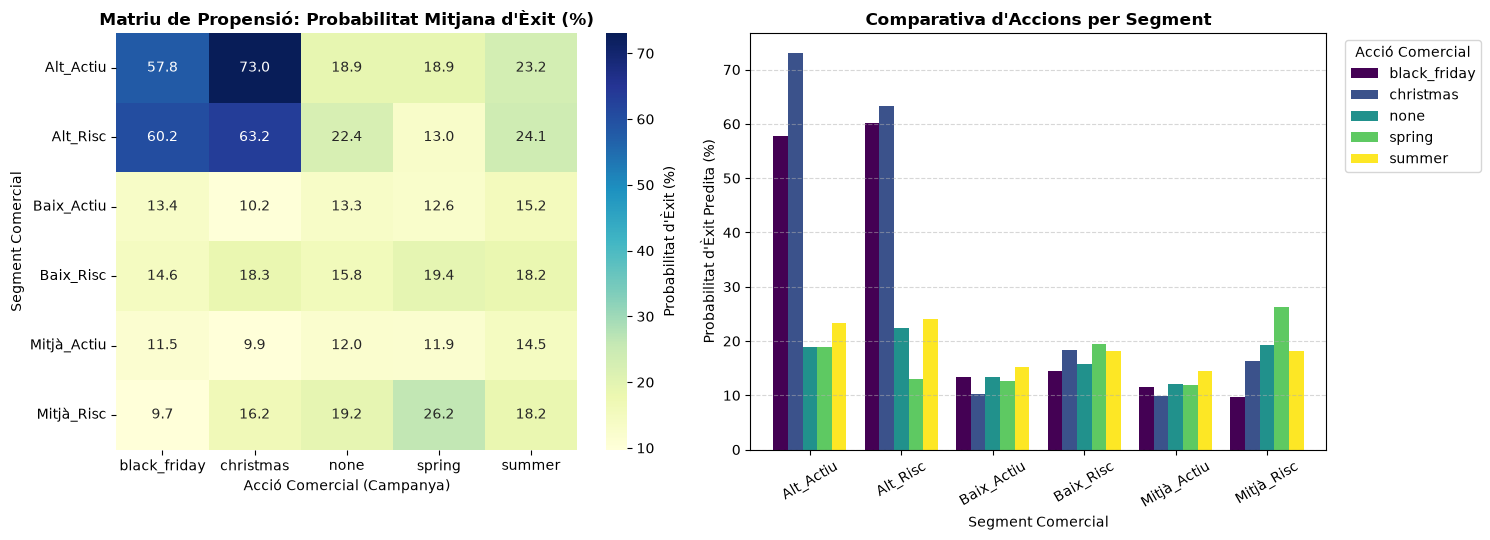

In [27]:
# Importació de Matplotlib i Seaborn
import matplotlib.pyplot as plt
import seaborn as sns

# Avaluem tots els clients nets contra totes les accions disponibles
df_clean = df_customers.loc[X.index].copy()
resultats = []

for accio in accions_disponibles:
    temp = df_clean.copy()
    temp["accio_comercial"] = accio
    X_temp = preprocessor.transform(temp[features])
    temp["prob_exit"] = model.predict_proba(X_temp)[:, 1]
    resultats.append(temp[["segment_comercial", "accio_comercial", "prob_exit"]])

df_eval = pd.concat(resultats, ignore_index=True)

# Creem una taula dinàmica (Pivot Table) amb el percentatge mitjà d'èxit
pivot_probs = (df_eval.pivot_table(index="segment_comercial", columns="accio_comercial", values="prob_exit", aggfunc="mean") * 100
)

# Generem la figura amb 2 gràfiques complementàries
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Gràfica Esquerra: Mapa de Calor (Matriu de decisió)
sns.heatmap(pivot_probs, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Probabilitat d'Èxit (%)"}, ax=axes[0])
axes[0].set_title("Matriu de Propensió: Probabilitat Mitjana d'Èxit (%)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Acció Comercial (Campanya)")
axes[0].set_ylabel("Segment Comercial")

# Gràfica Dreta: Barres agrupades per comparar accions dins de cada segment
pivot_probs.plot(kind="bar", ax=axes[1], colormap="viridis", width=0.8)
axes[1].set_title("Comparativa d'Accions per Segment", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Segment Comercial")
axes[1].set_ylabel("Probabilitat d'Èxit Predita (%)")
axes[1].legend(title="Acció Comercial", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()